# Complete modeling pipeline (leak-free)

Runs `src/evaluate.py`: preprocessing, feature engineering, LightGBM (two variants) and seasonal-naive baselines.

* **Validation (holdout):** 2015-06-16 to 2015-07-31, never used for fitting or early stopping.
* **Early stopping:** the 6 weeks before the holdout.
* **Rolling/EWM features** use only previous days (`shift(1)`); **store averages** use training dates only.
* **Caveat:** the `one_day_ahead` variant's lag/rolling features use the actual sales of the preceding days, so it assumes yesterday's sales are known. The `six_week_horizon` variant drops all sales-history features and is the fair comparison for forecasting the whole 46-day window at once.

Results are written to `results/metrics.json`.

In [1]:
import os, sys
os.chdir('..')
sys.path.insert(0, '.')

import matplotlib.pyplot as plt
import pandas as pd
from src.evaluate import main

results, valid, lgb_preds = main()

ROSSMANN DATA PREPROCESSING PIPELINE
📂 Loading datasets...


  ✓ Train: 1,017,209 rows × 9 columns
  ✓ Test:  41,088 rows × 8 columns
  ✓ Store: 1,115 rows × 10 columns

🔧 Handling missing values...
  Initial missing values: 2343
  ✓ Filled 3 missing CompetitionDistance values
  ✓ Filled 354 missing CompetitionOpenSinceMonth values
  ✓ Filled 354 missing CompetitionOpenSinceYear values
  ✓ Filled 544 missing Promo2SinceWeek values
  ✓ Filled 544 missing Promo2SinceYear values
  ✓ Filled 544 missing PromoInterval values
  ✓ Final missing values: 0

🔗 Merging with store information...


  ✓ Shape: (1017209, 9) → (1017209, 18)

🔗 Merging with store information...
  ✓ Shape: (41088, 8) → (41088, 17)



🚪 Filtering closed stores...
  ✓ Removed 172,817 closed store records
  ✓ Remaining: 844,392 rows



💰 Removing zero sales records...
  ✓ Removed 54 zero sales records
  ✓ Remaining: 844,338 rows

📅 Sorting by date...


  ✓ Data sorted chronologically

PREPROCESSING COMPLETE!

📊 Final Shapes:
  Train: 844,338 rows × 18 columns
  Test:  41,088 rows × 17 columns

FEATURE ENGINEERING PIPELINE

Initial columns: 18
📅 Extracting date features...


... (36 outputs left out)


✓ Training complete!
  Best iteration: 826
  Best score: defaultdict(<class 'collections.OrderedDict'>, {'train': OrderedDict({'rmse': np.float64(715.224459048038)}), 'valid': OrderedDict({'rmse': np.float64(918.8740256596924)})})


✓ Model saved to models/lightgbm_best_model.pkl


✓ Model saved to models/lightgbm_horizon_model.pkl


{
  "dataset": "Kaggle Rossmann Store Sales train.csv (open days, Sales > 0)",
  "splits": {
    "fit": {
      "rows": 728680,
      "from": "2013-01-31",
      "to": "2015-05-04"
    },
    "early_stopping": {
      "rows": 37470,
      "from": "2015-05-05",
      "to": "2015-06-15"
    },
    "validation": {
      "rows": 44738,
      "from": "2015-06-16",
      "to": "2015-07-31",
      "stores": 1115
    }
  },
  "metric_notes": "RMSPE = Kaggle metric (zero-sales days excluded); RMSE/MAE in sales units; MAPE in %.",
  "lightgbm_one_day_ahead": {
    "metrics": {
      "MAE": 593.7931,
      "RMSE": 845.4806,
      "RMSPE": 0.1273,
      "MAPE": 8.9152
    },
    "best_iteration": 560,
    "n_features": 49,
    "train_seconds": 112.6,
    "top10_features_gain": [
      {
        "feature": "Sales_EWM_7",
        "gain_share": 0.3388
      },
      {
        "feature": "Sales_RollingMean_14",
        "gain_share": 0.1728
      },
      {
        "feature": "Promo",
        "gain_sha

In [2]:
rows = {k: v['metrics'] for k, v in results.items() if isinstance(v, dict) and 'metrics' in v}
pd.DataFrame(rows).T[['RMSPE', 'RMSE', 'MAE', 'MAPE']].round(4)

,RMSPE,RMSE,MAE,MAPE
lightgbm_one_day_ahead,0.1273,845.4806,593.7931,8.9152
lightgbm_six_week_horizon,0.1389,939.3391,648.8122,9.7814
baseline_seasonal_naive_lag7,0.3974,2763.0013,2159.9591,31.2523
baseline_seasonal_naive_last_train_week,0.2901,2110.5872,1481.1467,20.7048


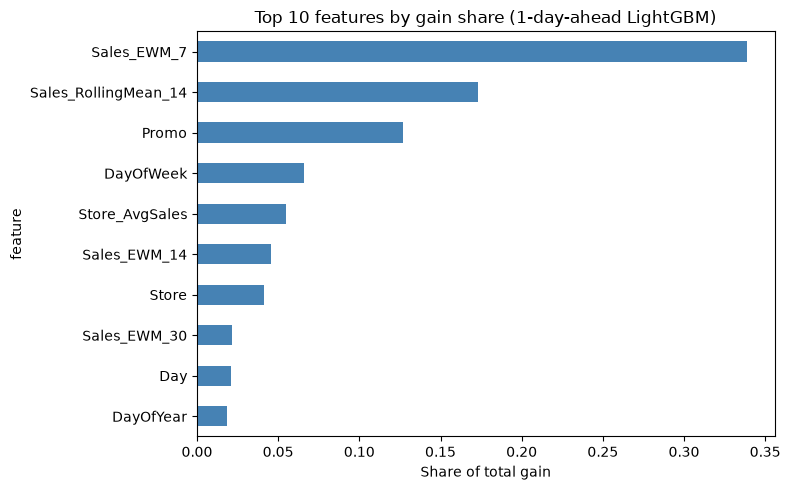

In [3]:
top = pd.DataFrame(results['lightgbm_one_day_ahead']['top10_features_gain'])
ax = top.iloc[::-1].plot(x='feature', y='gain_share', kind='barh', legend=False, figsize=(8, 5), color='steelblue')
ax.set_title('Top 10 features by gain share (1-day-ahead LightGBM)')
ax.set_xlabel('Share of total gain')
plt.tight_layout()
plt.show()

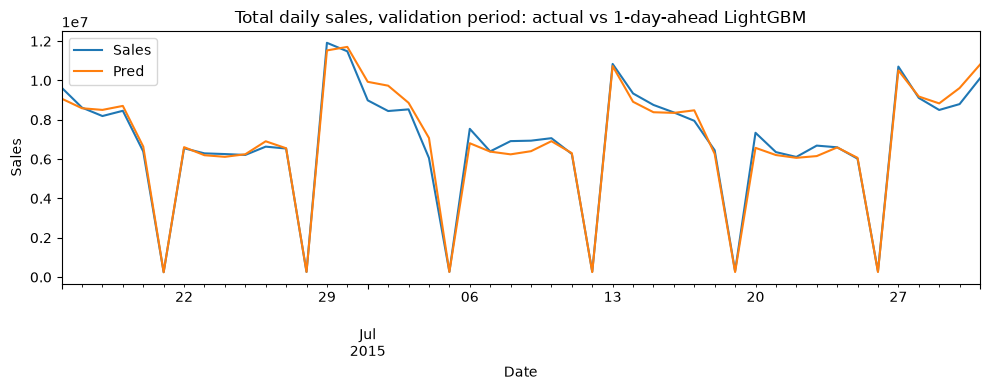

In [4]:
daily = valid.assign(Pred=lgb_preds).groupby('Date')[['Sales', 'Pred']].sum()
ax = daily.plot(figsize=(10, 4), title='Total daily sales, validation period: actual vs 1-day-ahead LightGBM')
ax.set_ylabel('Sales')
plt.tight_layout()
plt.show()